In [30]:
%reload_ext autoreload
%autoreload 2

import os
import sys
sys.path.append('../')
from pathlib import Path
import re
import numpy as np
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt

# my inference model modules
from latentEnthalpyModel import latentEnthalpyModel, BasalEvidence, PosteriorConfig
from Simulation import Simulation
from lowRankGPPrior import lowRankGPPrior
from GMMPrior import GMMPrior
from enthalpyPosterior import enthalpyPosterior
from posteriorObjective import posteriorObjective


# Part 1: Load data

Here we load the simulation data, grid, basal thermal evidence (as masks), and create the extent list for visualizing 2D data

In [31]:
data_path = "../data/"

# load simulations, grid, evidence masks, and pressure melting point
grid          = np.load(data_path + "grid.npz")
simulations   = np.load(data_path + "simulations.npz")
evidence_mask = np.load(data_path + "evidence_masks.npz")
pmp           = np.load(data_path + "pmp.npz")["pmp"]

# grid extent
extent_m  = [grid["x"].min(), grid["x"].max(), grid["y"].min(), grid["y"].max()]
extent_km = [x / 1e3 for x in extent_m]

# Part 2: standardization of simulation data

Show the min, max, and the max-min difference diagnostic

/home/donglaiyang/Documents/Georgia-Tech/Research/GMR-inference/src/Simulation.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


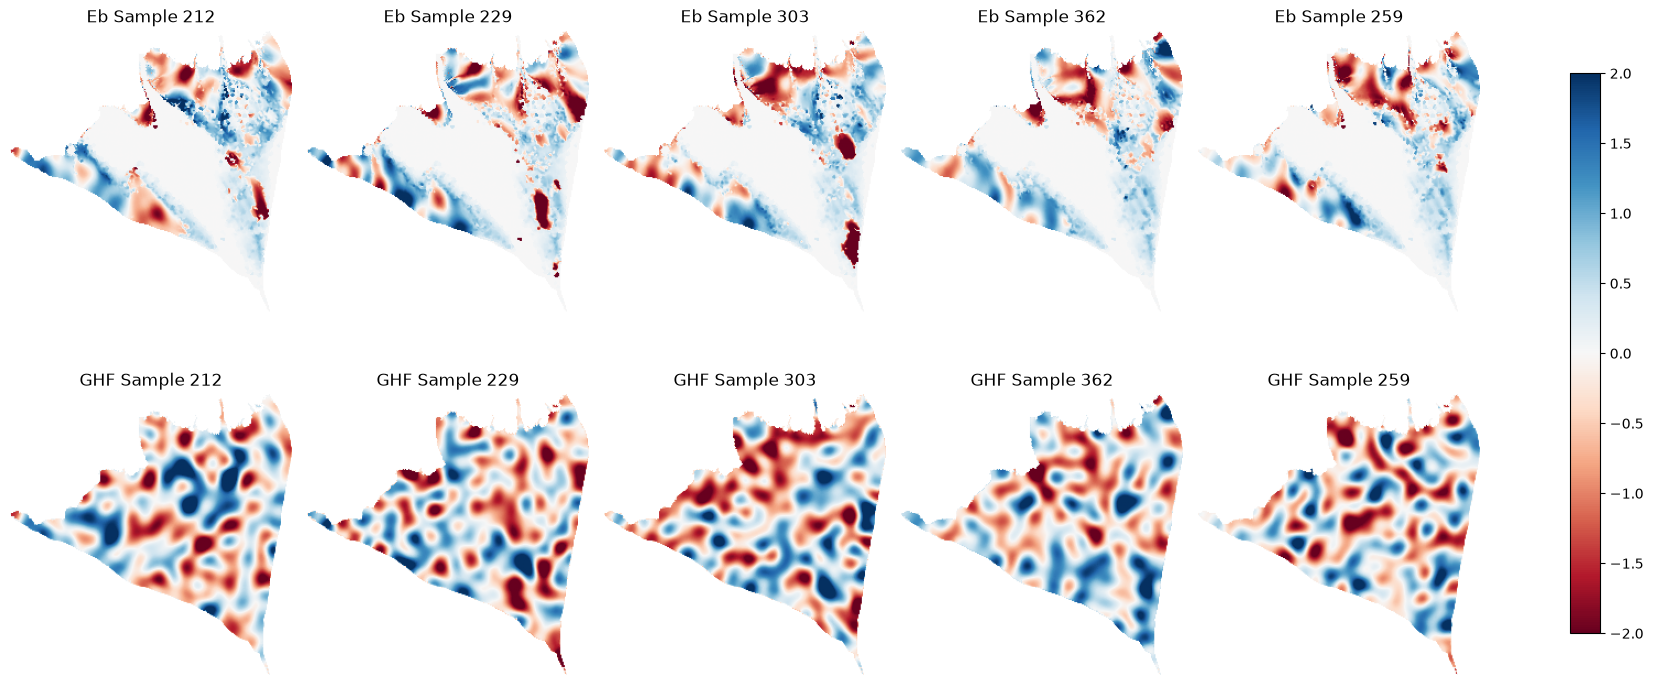

In [32]:
sims = Simulation(
    extent = extent_m,
    coord  = [grid["x"], grid["y"]]
)

sims.load_sim_data(
    X = [simulations["Eb"], simulations["GHF"]],
    labels = ["Eb", "GHF"],
    domain_mask = grid["mask"]
)

sims.show_data(n_samples_to_plot=5)


# Part 3: Density estimation on reduced-dimension simulation data

Find latent representation and tranformation via PAC and apply Gaussian Mixture Model 

In [33]:
latent_spaces = [100, 100]

sims.find_reduction_model_pca(
    n_latent = latent_spaces,
    show_scree=False)

In [34]:
# split the data into training, validation, and test sets
sims.split_data(train_ratio=0.8, validation_ratio=0.1, test_ratio=0.1)

gmm_n_gaussians = [3, 3]
sims.gmm_prior(n_gaussians = gmm_n_gaussians)

Splitting data: Total samples = 500
-------- Field 0: 
    Shape of X_train[0]: (400, 100)
    Shape of X_validation[0]: (50, 100)
    Shape of X_test[0]: (50, 100)
-------- Field 1: 
    Shape of X_train[1]: (400, 100)
    Shape of X_validation[1]: (50, 100)
    Shape of X_test[1]: (50, 100)
-----------------------------
-----------------------------
Fitting GMMs for each field
--------- Field 0, number of Gaussians: 3
--------- Field 1, number of Gaussians: 3


# Part 4: Creating randomized basal thermal evidence for validation

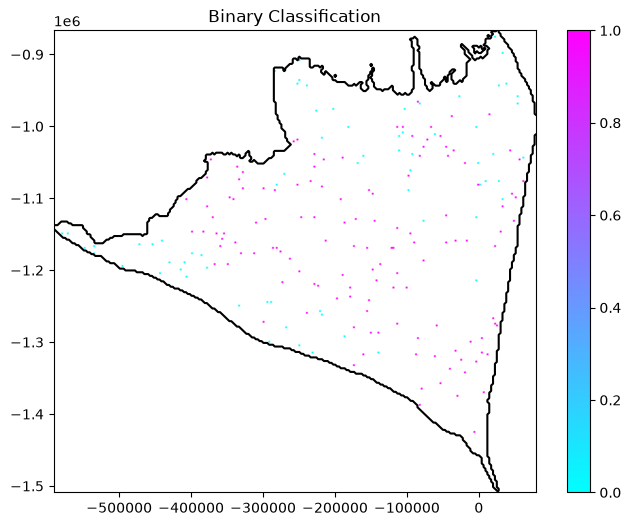

In [ ]:
from observationOperator import enthalpy_to_delta_temperature_operator, temperature_binary_hard_operator
import torch

# create random scattered points
n_points = 200
rng = np.random.default_rng(seed=42)
idx_in_domain = np.arange(sims.ndim_ori)[sims.domain_mask.flatten()]
idx_random = rng.choice(idx_in_domain, size=n_points, replace=False)

basal_location = np.zeros(sims.ndim_ori)
basal_location[idx_random] = True
basal_location[basal_location==0] = np.nan

# applying this to a random sample of the validation set 
# to get the thawed and frozen evidence
idx_validation = np.arange(sims.n_samples_validation)
idx_validation_random = rng.choice(idx_validation, size=1, replace=False)

Eb_sample = sims.X_validation[0][idx_validation_random[0]]
Eb_sample = sims.pca_x[0].inverse_transform(Eb_sample.reshape(1, -1))
Eb_sample = sims.scaling_models[0].inverse_transform(Eb_sample).T

delta_T = enthalpy_to_delta_temperature_operator(
    Eb_sample.flatten(), 
    pmp.flatten(), 
    istorch=False
)

binary_class = temperature_binary_hard_operator(
    delta_T = torch.from_numpy(delta_T.flatten()),
    dT_cutoff = 0.5,
)

basal_evidence_sample = binary_class.numpy() * basal_location

plt.figure(figsize=(8,6))
plt.imshow(basal_evidence_sample.reshape(sims.nx, sims.ny), 
           cmap='cool',
           origin="lower", 
           extent=sims.extent)
for x, y in sims.domain_bound_line:
    plt.plot(x, y, color='black')
plt.colorbar()
plt.title("Binary Classification")
plt.show()

In [79]:
n_points = 200
rng_locations = np.random.default_rng(seed=42)

idx_in_domain = np.flatnonzero(sims.domain_mask.ravel())

basal_location_all = np.full(
    (sims.n_samples_validation, sims.ndim_ori),
    np.nan,
    dtype=np.float32,
)

for i in range(sims.n_samples_validation):
    idx_random = rng_locations.choice(
        idx_in_domain,
        size=n_points,
        replace=False,
    )
    basal_location_all[i, idx_random] = 1.0

# Same shape as basal_location_all:
# (n_samples_validation, ndim_ori)
thawed_all = np.zeros(basal_location_all.shape, dtype=bool)
frozen_all = np.zeros(basal_location_all.shape, dtype=bool)

pmp_flat = np.asarray(pmp).ravel()

with torch.no_grad():
    for i in range(sims.n_samples_validation):
        # Reconstruct physical basal enthalpy.
        Eb_sample = sims.X_validation[0][i]
        Eb_sample = sims.pca_x[0].inverse_transform(
            Eb_sample.reshape(1, -1)
        )
        Eb_sample = sims.scaling_models[0].inverse_transform(
            Eb_sample
        ).ravel()

        # Enthalpy -> temperature difference.
        delta_T = enthalpy_to_delta_temperature_operator(
            Eb_sample,
            pmp_flat,
            istorch=False,
        )

        # Temperature difference -> binary classification.
        binary_class = temperature_binary_hard_operator(
            delta_T=torch.from_numpy(np.asarray(delta_T).ravel()),
            dT_cutoff=0.5,
        )
        binary_class = binary_class.detach().cpu().numpy().ravel()

        if binary_class.size != basal_location_all.shape[1]:
            raise ValueError(
                f"Sample {i}: classification has {binary_class.size} "
                f"points; expected {basal_location_all.shape[1]}."
            )

        # Observed locations retain 0/1; all others become NaN.
        basal_evidence_sample = binary_class * basal_location_all[i]

        # NaN compares unequal to both 0 and 1, so unobserved
        # locations are False in both masks.
        thawed_all[i] = basal_evidence_sample == 1
        frozen_all[i] = basal_evidence_sample == 0

# save the frozen and thawed masks to files
np.save("../data/synthetic/thawed_all.npy", thawed_all)
np.save("../data/synthetic/frozen_all.npy", frozen_all)



# Part 5: Solve for MAP and posterior distributions

In [82]:
import torch
import scipy as sp
def to_numpy(value):
    if torch.is_tensor(value):
        return value.detach().cpu().numpy()
    return np.asarray(value)

# likelihood
for i in range(sims.n_samples_validation):

    print("Processing sample", i, "........")

    thawed_mask = thawed_all[i]
    frozen_mask = frozen_all[i]
    thawed_frac_area = np.where(thawed_mask, 1, 0)
    frozen_frac_area = np.where(frozen_mask, 1, 0)

    # prior distributions
    gp_prior = lowRankGPPrior(
        domain_mask = sims.domain_mask,
        hx = sims.delta_x,
        hy = sims.delta_y,
        n_mode = 100,
        pca_basis = sims.pca_x[0].components_.T, # only look at Eb
        sigma_amp = 0.1,
        nu = 0.1,
        rho = 1.0,
    )

    sim_prior = GMMPrior(
        gmm = sims.gmms[0]
    )

    evidence = BasalEvidence.from_arrays(
        Tpmp = pmp,
        thawed_mask = thawed_mask,
        frozen_mask = frozen_mask,
        dw = thawed_frac_area,
        df = frozen_frac_area,
    )

    config = PosteriorConfig(
        beta = 0.5,
        beta_w = 0.005
    )

    forward_model = latentEnthalpyModel(
        pca = sims.pca_x[0],
        gp = gp_prior,
        scaler = sims.scaling_models[0],
        Tpmp = pmp,
    )

    posterior = enthalpyPosterior(
        forward_model = forward_model,
        evidence = evidence,
        gmm = sim_prior,
        gp  = gp_prior,
        config = config,
    )

    # initialize posterior guess
    n_gmm_dim = sims.ndim_reduced[0]
    n_gp_dim  = gp_prior.n_mode

    objective = posteriorObjective(
        posterior = posterior,
    )


    theta0 = np.concatenate([
        torch.zeros(n_gp_dim),
        torch.zeros(n_gmm_dim)
    ])

    # Maximmum a posteriori (MAP) estimation
    result = sp.optimize.minimize(
        fun = objective.value,
        x0  = theta0,
        jac = objective.gradient,
        method = "L-BFGS-B",
            options={
            # "maxiter": 500,
            # "maxfun": 500,
            "disp": True,
            "ftol": 1e-9,
            "gtol": 1e-6,
            "maxls": 10,
        },
    )

    # laplace approximation
    map_z_gp = result.x[:n_gp_dim]
    map_z_gmm = result.x[n_gp_dim:]
    enthalpy_map = forward_model.enthalpy(map_z_gp, map_z_gmm)
    physical_result_MAP = forward_model.physical_state(map_z_gp, map_z_gmm)

    # Laplace approximation: compute the negative inverse of the Hessian at the MAP estimate
    laplace_samples = posterior.laplace_approx(
        map_z_gp, 
        map_z_gmm, 
        n_sample=200
    )


    # Store one flattened enthalpy field per posterior draw.
    posterior_enthalpy = np.empty(
        (len(laplace_samples), Eb_sample.size),
        dtype=np.float32,
    )

    with torch.no_grad():
        for j, sample in enumerate(laplace_samples):
            z_gp = sample[posterior.gp_dim_index]
            z_gmm = sample[posterior.gmm_dim_index]

            state = forward_model.physical_state(z_gp, z_gmm)
            enthalpy = to_numpy(state["enthalpy"]).ravel()

            if enthalpy.size != Eb_sample.size:
                raise ValueError(
                    f"Draw {j}: expected {Eb_sample.size} enthalpy values, "
                    f"got {enthalpy.size}."
                )
            posterior_enthalpy[j] = enthalpy

    # get the groundtruth basal enthalpy just for the record
    Eb_sample = sims.X_validation[0][i]
    Eb_sample = sims.pca_x[0].inverse_transform(
        Eb_sample.reshape(1, -1)
    )
    Eb_sample = sims.scaling_models[0].inverse_transform(
        Eb_sample
    ).ravel()

    # save results
    # save sigma_amp, map, and laplace_samples
    result_dict = {
        "sigma_amp": gp_prior.sigma_amp,
        "enthalpy_map": enthalpy_map,
        "physical_result_MAP": physical_result_MAP,
        "laplace_samples": laplace_samples,
        "thawed_mask": thawed_mask,
        "frozen_mask": frozen_mask,
        # also the ground truth basal enthalpy
        "Eb_sample": Eb_sample
    }
    result_dict["posterior_enthalpy"] = posterior_enthalpy
    result_dict["forward_model"] = forward_model
    result_dict["gp_dim_index"] = posterior.gp_dim_index
    result_dict["gmm_dim_index"] = posterior.gmm_dim_index

    np.save(f"../data/synthetic/result_{i}.npy", result_dict)


Processing sample 0 ........
Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


/tmp/ipykernel_1669170/1871169504.py:77: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = sp.optimize.minimize(


Processing sample 1 ........
Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


/tmp/ipykernel_1669170/1871169504.py:77: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = sp.optimize.minimize(


Processing sample 2 ........
Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


/tmp/ipykernel_1669170/1871169504.py:77: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = sp.optimize.minimize(


... (90 outputs left out)

Processing sample 48 ........
Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


/tmp/ipykernel_1669170/1871169504.py:77: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = sp.optimize.minimize(


Processing sample 49 ........
Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


/tmp/ipykernel_1669170/1871169504.py:77: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = sp.optimize.minimize(


# Analyze results
Here we use Continuous Ranked Probability Score (CRPS) to quantify the accuracy of posterior prediction given a ground truth.

In [88]:
from scores.probability import crps_cdf
from validation import basal_enthalpy_crps

i = 10

saved = np.load(
    f"../data/synthetic/result_{i}.npy",
    allow_pickle=True,
).item()

domain_shape = sims.domain_mask.shape

posterior_fields = saved["posterior_enthalpy"].reshape(
    -1, *domain_shape
)
ground_truth = saved["Eb_sample"].reshape(domain_shape)

crps_map, mean_crps = basal_enthalpy_crps(
    posterior_samples=posterior_fields,
    ground_truth=ground_truth,
    domain_mask=sims.domain_mask,
    n_thresholds=512,
    chunk_size=512,
)



/home/donglaiyang/Documents/Georgia-Tech/Research/petermann-inference/.venv/lib/python3.11/site-packages/scores/probability/crps_impl.py:366: UserWarning: numba is not available. Using slower exact CRPS implementation.
  warnings.warn("numba is not available. Using slower exact CRPS implementation.")
/home/donglaiyang/Documents/Georgia-Tech/Research/petermann-inference/.venv/lib/python3.11/site-packages/scores/probability/crps_impl.py:366: UserWarning: numba is not available. Using slower exact CRPS implementation.
  warnings.warn("numba is not available. Using slower exact CRPS implementation.")
/home/donglaiyang/Documents/Georgia-Tech/Research/petermann-inference/.venv/lib/python3.11/site-packages/scores/probability/crps_impl.py:366: UserWarning: numba is not available. Using slower exact CRPS implementation.
  warnings.warn("numba is not available. Using slower exact CRPS implementation.")
/home/donglaiyang/Documents/Georgia-Tech/Research/petermann-inference/.venv/lib/python3.11/sit

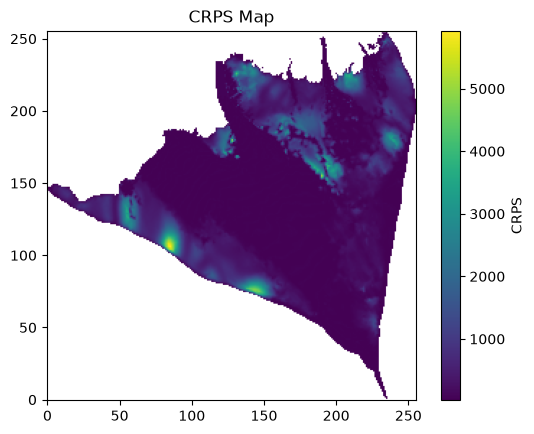

In [89]:
plt.imshow(crps_map, origin='lower')
plt.colorbar(label='CRPS')
plt.title('CRPS Map')
plt.show()